Viewed batch-norm.ipynb:1-300
Viewed batch-norm.ipynb:301-600
Searched for ""cell_type":"
Viewed batch-norm.ipynb:1190-1320
Viewed batch-norm.ipynb:2210-2289

本篇 [batch-norm.ipynb](file:///Users/songchao/WorkSpace/Python/DeepLearn/pytorch/chapter_convolutional-modern/batch-norm.ipynb) 主要介绍了深度学习中里程碑式的技术 —— **批量规范化（Batch Normalization, BN）**。以下是该 Notebook 的核心内容总结：

---

### 一、为什么需要批量规范化（动机与挑战）

在训练极深神经网络（特别是数十层甚至百层以上）时，主要面临以下痛点：
1. **数据与中间变量分布剧烈变动**：深层网络在前向传播时，中间隐藏层变量的数值范围波动很大；若某一层的值是另一层的上百倍，往往需要非常保守的学习率，导致收敛极其缓慢。
2. **易过拟合与正则化需求**：复杂深层网络参数繁多，容易发生过拟合，需要更高效的正则化手段。
3. **批量规范化的解决思路**：在每个小批量（mini-batch）内，对层中间特征主动居中（零均值）并缩放（单位方差），使整个神经网络各层的中间输出更加稳定，从而支持使用更大的学习率加速收敛。

---

### 二、数学原理与计算过程

批量规范化作用于每个小批量 `B`。假设输入为 `x`，具体计算分为两步：

```text
1. 计算当前小批量的均值与方差（引入微小常数 ϵ > 0 防止除零）：
   μ_B = (1 / |B|) · ∑_{x ∈ B} x
   σ_B² = (1 / |B|) · ∑_{x ∈ B} (x - μ_B)² + ϵ

2. 标准化与仿射变换（引入可学习参数 γ 和 β）：
   x̂ = (x - μ_B) / √(σ_B² + ϵ)
   y = BN(x) = γ ⊙ x̂ + β
```

* **拉伸参数 `γ` (scale) 与偏移参数 `β` (shift)**：形状与特征相同，作为模型参数参与反向传播与梯度更新，以恢复网络所需的特征表达能力（避免单纯限制在 0 均值与单位方差导致表达能力受限）。
* **批量大小要求**：BN 依赖批量统计量，若批量大小为 1，减去均值后所有单元全为 0，无法学习；通常适合在 50~100 左右的中等批量下运行。

---

### 三、全连接层与卷积层的区别

在网络架构中，批量规范化通常置于**仿射/卷积变换之后、激活函数之前**：`h = ϕ(BN(W·x + b))`。

| 网络层类型 | 输入形状 | 规范化统计维度 | 参数 `γ` 与 `β` 的形状 |
| :--- | :--- | :--- | :--- |
| **全连接层** | `(batch_size, num_features)` | 样本维度（dim=0），每个特征独立计算均值和方差 | `(1, num_features)` |
| **卷积层** | `(batch_size, channels, H, W)` | 跨样本与空间维度（dim=(0, 2, 3)），每个**通道**独立统计 | `(1, channels, 1, 1)` |

* **卷积层特点**：同一个通道的所有空间位置 `(H, W)` 共享同一个均值、方差、拉伸参数 `γ` 和偏移参数 `β`，符合卷积平移不变性的先验。

---

### 四、训练模式 vs 预测模式

批量规范化在两种模式下的行为有显著差异：

1. **训练模式（Training）**：
   * 使用当前小批量数据的均值 `μ_B` 和方差 `σ_B²` 进行标准化。
   * 小批量统计量的波动引入了微弱的随机噪声，具有天然的正则化副作用，有助于降低过拟合。
   * 同时使用指数移动平均（EMA）维护全局的均值与方差：
     ```text
     moving_mean = momentum · moving_mean + (1 - momentum) · μ_B
     moving_var  = momentum · moving_var  + (1 - momentum) · σ_B²
     ```
2. **预测/评估模式（Inference）**：
   * 预测时通常单样本或小批量输入，不再计算批次内均值和方差，而是直接使用训练期间累积的 `moving_mean` 和 `moving_var`，保证预测结果的确定性。

---

### 五、代码实现与对比

Notebook 演示了两种实现方式并将其应用在经典的 [LeNet](file:///Users/songchao/WorkSpace/Python/DeepLearn/pytorch/chapter_convolutional-modern/batch-norm.ipynb#L254-L262) 模型上：

1. **从零实现（Custom BatchNorm）**：
   * 编写 `batch_norm` 函数，使用 `torch.is_grad_enabled()` 自动判断当前属于训练模式还是评估模式。
   * 封装自定义 `BatchNorm(nn.Module)`，管理 `gamma`、`beta` 参数以及 `moving_mean`、`moving_var` 缓冲区。
   * 训练结果：在 Fashion-MNIST 数据集上，将学习率设为较大的 `lr = 1.0` 依然能够快速稳定收敛，达到约 90.0% 的训练准确率和 86.0% 的测试准确率。
2. **简明实现（PyTorch 高级 API）**：
   * 卷积层直接使用 `nn.BatchNorm2d(channels)`。
   * 全连接层直接使用 `nn.BatchNorm1d(features)`。
   * **效率优势**：原生 PyTorch API 采用底层 C++/CUDA 算子融合实现，样本吞吐率从自定义 Python 实现的约 40,800 examples/s 提升至 71,480 examples/s。

---

### 六、关于原理的学术争议

* **原始动机与解释**：原论文（Ioffe & Szegedy, 2015）将其归功于减少了“内部协变量偏移”（Internal Covariate Shift, ICS）。
* **后续争论与修正**：
  * 后续研究（如 Santurkar 等人, 2018）表明，BN 的有效性可能与减少内部协变量偏移关系不大。
  * 真实的主要优势在于：它使损失函数的**损失曲面更加平滑（Lipschitz 平滑性）**，梯度变得更具可预测性且方差更小，因而允许采用更大的学习率和更激进的优化策略，同时小批量随机性兼具正则化效果。

In [1]:
import torch
from torch import nn
from d2l import torch as d2l



In [10]:
def batch_norm(X, gamma, beta, moving_mean, moving_var, eps, momentum):
    if not torch.is_grad_enabled():
        X_hat = (X-moving_mean) / torch.sqrt(moving_var + eps)
    
    else:
        assert len(X.shape) in (2,4)
        if len(X.shape) == 2:
            mean = X.mean(dim=0)
            var = ((X-mean)**2).mean(dim=0)
        else:
            mean = X.mean(dim=(0,2,3), keepdim=True)
            var = ((X-mean)**2).mean(dim=(0,2,3), keepdim=True)
        X_hat = (X-mean) / torch.sqrt(var+eps)
        moving_mean = moving_mean * momentum + (1.0 -momentum)*mean
        moving_var = momentum * moving_var + (1.0 -momentum)*var
    Y = gamma*X_hat+beta
    return Y, moving_mean.data, moving_var.data

In [3]:
class BatchNorm(nn.Module):

    def __init__(self, num_features, num_dims):
        super().__init__()
        if num_dims == 2:
            shape = (1, num_features)
        else:
            shape = (1, num_features, 1, 1)
        self.gamma = nn.Parameter(torch.ones(shape))
        self.beta = nn.Parameter(torch.zeros(shape))
        self.moving_mean = torch.zeros(shape)
        self.moving_var = torch.ones(shape)
    
    def forward(self, X):
        if self.moving_mean.device !=X.device:
            self.moving_mean = self.moving_mean.to(X.device)
            self.moving_var = self.moving_var.to(X.device)
        Y, self.moving_mean, self.moving_var = batch_norm(X, 
            self.gamma, self.beta, self.moving_mean, self.moving_var,
            eps=1e-5, momentum=0.9)
        return Y




In [4]:

net = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5), BatchNorm(6, num_dims=4), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), BatchNorm(16, num_dims=4), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2), nn.Flatten(),
    nn.Linear(16*4*4, 120), BatchNorm(120, num_dims=2), nn.Sigmoid(),
    nn.Linear(120, 84), BatchNorm(84, num_dims=2), nn.Sigmoid(),
    nn.Linear(84, 10)
)

loss 0.252, train acc 0.906, test acc 0.833
4898.1 examples/sec on cpu


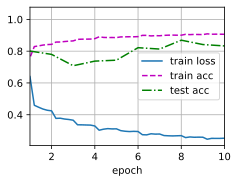

In [11]:
lr, num_epochs, batch_size = 1.0, 10, 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
d2l.train_ch6(net, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

以下是 [batch-norm.ipynb](file:///Users/songchao/WorkSpace/Python/DeepLearn/pytorch/chapter_convolutional-modern/batch-norm.ipynb) 课后练习题的逐题详尽解答与分析：

---

### 练习 1：在使用批量规范化之前，我们是否可以从全连接层或卷积层中删除偏置参数？为什么？

**解答**：
**完全可以，而且在工程实践中通常强烈建议显式设置 `bias=False`。**

**原理推导**：
设全连接层或卷积层的线性输出为 `y = W·x + b`（其中 `b` 为偏置）。紧接着对 `y` 进行批量规范化操作：
```text
1. 计算批次均值：
   μ_B = (1 / |B|) · ∑_{i ∈ B} (W·x_i + b)
       = ((1 / |B|) · ∑_{i ∈ B} W·x_i) + b

2. 计算中心化输出：
   y_i - μ_B = (W·x_i + b) - [((1 / |B|) · ∑_{i ∈ B} W·x_i) + b]
             = W·x_i - (1 / |B|) · ∑_{i ∈ B} W·x_i
```
从推导可以看出，**偏置项 `b` 在减去批次均值 `μ_B` 的步骤中被严格抵消了**。

此外，批量规范化层本身就带有可学习的偏移参数 `β`（shift），它已经完全接管并恢复了偏置的作用。因此，在 BN 之前的卷积层或全连接层中保留 `bias` 不仅对最终特征毫无影响，还会造成参数冗余和不必要的梯度计算。

---

### 练习 2：比较 LeNet 在使用和不使用批量规范化情况下的学习率

#### 1. 学习率有多高？
* **未添加 BN**：传统 LeNet 采用 Sigmoid 激活函数，当学习率过大（如 `lr ≥ 0.5` 或 `1.0`）时，前向传播的输出容易迅速落入 Sigmoid 的两侧饱和区（导数趋近于 0），引发严重的**梯度消失**，导致网络无法收敛；通常需要将学习率限制在较小区间（如 `0.1` 甚至更低）。
* **添加 BN 后**：BN 强行将隐藏层输出拉回均值为 0、方差为 1 的中心区间，避开了激活函数的饱和失效区，使得优化过程极为稳定。即使采用极高学习率（如教程中直接使用的 `lr = 1.0`，甚至尝试 `1.5 ~ 2.0`），模型依然能高速稳定收敛。

#### 2. 训练和测试准确度的提高
* **收敛速度大幅提升**：加入 BN 后，通常在第 2~3 个 epoch 准确率就能蹿升至 80% 以上，而无 BN 的网络收敛过程相对平缓迟滞。
* **最终精度轻微提升**：小批量均值与方差引入的随机噪声带来了天然的正则化效果，能够有效缓解小模型的过拟合，使测试集泛化精度得到提高。

---

### 练习 3：我们是否需要在每个层中进行批量规范化？尝试一下？

**解答**：
**并不是所有层都需要添加，尤其在某些关键位置绝对不能添加**：

1. **输出层（分类/回归输出头）**：
   * 绝对**不能**添加 BN。若对最终输出 logits 做 BN，会强制将其均值拉平为 0，破坏各类别之间的相对绝对置信度差值，严重干扰 Softmax 分类概率输出。
2. **输入层**：
   * 通常不需要。因为输入特征一般已经通过全局数据预处理（例如减去数据集全局均值并除以标准差）进行了标准化，输入分布本身是静态稳定的。
3. **极浅层与极深层的差异**：
   * 靠近输入端的浅层特征漂移较小，不加 BN 往往也能正常训练；
   * 随着网络加深，多层矩阵连乘会导致特征分布方差剧烈放缩，因此**越是深层网络，BN 的价值越关键**。

---

### 练习 4：可以通过批量规范化来替换暂退法（Dropout）吗？行为会如何改变？

**解答**：
**在现代卷积神经网络（如 ResNet）中，BN 在很大程度上已经替代了 Dropout。**

* **机制差异**：
  * **Dropout**：在训练中随机以概率 `p` 将神经元激活值置零，破坏神经元之间的共适应性，属于硬性丢弃连接的显式正则化。
  * **BN**：标准化时依赖当前小批量的均值 `μ_B` 和方差 `σ_B²`，每个样本在不同 batch 组合下看到的均值和方差均带有轻微的采样噪声，这等价于对特征注入了隐式随机扰动，具有平滑的正则化效果。
* **行为变化**：
  * BN 兼具加速收敛与正则化双重功效；而 Dropout 会暂时降低网络容量，往往会使网络收敛速度变慢。
* **混用冲突（方差偏移问题）**：
  * 学术界研究指出，若在相邻层同时使用 Dropout 与 BN，Dropout 会改变测试阶段特征的方差预期，导致 BN 在测试阶段累积的移动方差出现系统性偏差（Variance Shift）。因此现代网络通常优先使用 BN，仅在全连接层或无 BN 的模块中按需使用微量 Dropout。

---

### 练习 5：确定参数 `beta` 和 `gamma`，并观察和分析结果

在 Notebook 训练完成后，打印第一个 BN 层的参数：
```python
net[1].gamma.reshape((-1,)), net[1].beta.reshape((-1,))
```
* **数值表现**：
  * `gamma` 初始为全 1，训练后向 `[1.65 ~ 4.18]` 附近发散；
  * `beta` 初始为全 0，训练后发散至 `[-3.67 ~ 2.17]`。
* **现象分析**：
  * 如果只做纯粹的零均值、单位方差标准化，紧接着接入 Sigmoid 函数时，激活值会被限制在 `x ∈ [-2, 2]` 区间内，而该区间主要表现为**近乎线性的变换**（`Sigmoid(x) ≈ 0.5 + 0.25x`），这会严重削弱神经网络的非线性表达能力。
  * 通过反向传播自主学习 `gamma`（拉伸尺度）和 `beta`（平移偏移），网络能够自主权衡：将特征拉伸移动到激活函数的非线性弯曲区间甚至饱和区间，既保留了数值稳定性，又最大化了非线性表征能力。

---

### 练习 6：查看高级 API 中有关 `BatchNorm` 的在线文档，以查看其他批量规范化的应用

在 PyTorch 高级 API 中，除了本节使用的 `nn.BatchNorm1d` 和 `nn.BatchNorm2d` 之外，还有以下重要应用与变体：

1. **`nn.BatchNorm3d`**：
   * 针对 5D 张量 `(N, C, D, H, W)`，常用于 3D 医学影像（如 CT/MRI 容积扫描）或时空视频特征的规范化。
2. **`nn.SyncBatchNorm`（分布式同步批规范化）**：
   * **适用场景**：多 GPU / 分布式并行训练。
   * **核心意义**：在多卡训练且单卡显存受限时（例如目标检测单卡 batch_size 仅为 2 或 4），单卡 BN 的统计量方差过大。`SyncBatchNorm` 利用 All-Gather 原语在所有工作卡之间同步样本统计量，计算全局均值和方差，显著提高大模型/检测模型的训练稳定性。
3. **重要超参数控制**：
   * `momentum`：PyTorch 中默认设为 `0.1`，用于计算移动平均（`moving_mean = (1 - momentum) · moving_mean + momentum · new_mean`）。
   * `affine`：布尔值，是否分配可学习的 `weight` (γ) 和 `bias` (β)。
   * `track_running_stats`：若设为 `False`，则即使在预测模式下也强制使用当前批次的统计量。

---

### 练习 7：研究思路：可以应用的其他“规范化”转换？可以应用概率积分变换吗？全秩协方差估计可以么？

#### 1. 其他常见的“规范化”族谱（Normalizations）
* **Layer Normalization (LN)**：沿特征和通道维度独立于每个样本做归一化，与 batch size 完全解耦，是当前 Transformer 与主流大语言模型（LLM）的标配。
* **Instance Normalization (IN)**：单样本单通道独立统计，常用于去除图像风格特征（在图像风格迁移 Style Transfer 中表现优异）。
* **Group Normalization (GN)**：将通道划分为若干组并在组内计算统计量，在超高分辨率或极小批量的视觉检测任务中替代 BN。
* **RMSNorm**：舍弃减去均值的操作，仅对均方根进行缩放，计算更加轻量高效，被 LLaMA 等现代开源 LLM 广泛采纳。

#### 2. 概率积分变换（Probability Integral Transform, PIT）
* **原理**：理论上任何连续随机变量 `X`，通过其自身的累积分布函数（CDF）变换 `U = F_X(X)` 后，其值都会严格服从 `[0, 1]` 上的均匀分布。
* **可行性与局限**：
  * **计算极其昂贵且难以微分**：神经网络隐藏层的概率分布随训练不断漂移，其实时经验 CDF 难以在低开销下准确构建；
  * **反向传播受阻**：经验分布函数多呈阶跃状，求导困难；
  * **信息损失**：强行映射到均匀分布可能抹平特征的高阶矩信息，因此实用性有限。

#### 3. 全秩协方差估计（Full-rank Covariance / 白化 Whitening）
* **原理**：标准 BN 假设各神经元/通道相互独立，只沿对角线做了一阶与二阶矩归一化。若计算完整的样本协方差矩阵 `Σ` 并通过特征分解或 SVD 进行白化（Whitening，如 `Σ^(-1/2) · (x - μ)`），可以彻底去除特征之间的冗余相关性，使协方差矩阵成为单位阵 `I`。
* **可行性与局限**：
  * **计算复杂度高**：对维度为 `d` 的特征进行矩阵求逆或 SVD 分解的复杂度高达 `O(d³)`，在大通道深层网络中计算负担极大；
  * **数值稳定性较差**：矩阵求逆的梯度反向传播容易发生奇异或梯度爆炸。
  * **相关前沿研究**：针对该问题，学术界提出了如 **Decorrelated Batch Normalization (DBN)** 和基于牛顿迭代的 **Iterative Normalization (IterNorm)**，虽证明了去相关性能进一步提升模型表现，但在工业界因开销考量仍以标准对角化 BN 为主。